In [113]:
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

In [114]:
print(pd.__version__)
print(sklearn.__version__)

3.0.6
1.9.1


In [115]:
columns = ['ip_mean', 'ip_std', 'ip_kurtosis', 'ip_skew','dm_mean', 'dm_std', 'dm_kurtosis', 'dm_skew', 'label']

In [116]:
df = pd.read_csv('data/HTRU_2.csv', header=None, names=columns)

In [138]:
print(df.shape)
print(df.head())

(17898, 9)
      ip_mean     ip_std  ip_kurtosis   ip_skew   dm_mean     dm_std  \
0  140.562500  55.683782    -0.234571 -0.699648  3.199833  19.110426   
1  102.507812  58.882430     0.465318 -0.515088  1.677258  14.860146   
2  103.015625  39.341649     0.323328  1.051164  3.121237  21.744669   
3  136.750000  57.178449    -0.068415 -0.636238  3.642977  20.959280   
4   88.726562  40.672225     0.600866  1.123492  1.178930  11.468720   

   dm_kurtosis     dm_skew  label  
0     7.975532   74.242225      0  
1    10.576487  127.393580      0  
2     7.735822   63.171909      0  
3     6.896499   53.593661      0  
4    14.269573  252.567306      0  


In [119]:
df.dtypes

ip_mean        float64
ip_std         float64
ip_kurtosis    float64
ip_skew        float64
dm_mean        float64
dm_std         float64
dm_kurtosis    float64
dm_skew        float64
label            int64
dtype: object

In [120]:
df.isna().sum()

ip_mean        0
ip_std         0
ip_kurtosis    0
ip_skew        0
dm_mean        0
dm_std         0
dm_kurtosis    0
dm_skew        0
label          0
dtype: int64

In [121]:
df.duplicated().sum()

np.int64(0)

In [122]:
df.describe()

,ip_mean,ip_std,ip_kurtosis,ip_skew,dm_mean,dm_std,dm_kurtosis,dm_skew,label
count,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000
mean,111.079968,46.549532,0.477857,1.770279,12.614400,26.326515,8.303556,104.857709,0.091574
std,25.652935,6.843189,1.064040,6.167913,29.472897,19.470572,4.506092,106.514540,0.288432
min,5.812500,24.772042,-1.876011,-1.791886,0.213211,7.370432,-3.139270,-1.976976,0.000000
25%,100.929688,42.376018,0.027098,-0.188572,1.923077,14.437332,5.781506,34.960504,0.000000
50%,115.078125,46.947479,0.223240,0.198710,2.801839,18.461316,8.433515,83.064556,0.000000
75%,127.085938,51.023202,0.473325,0.927783,5.464256,28.428104,10.702959,139.309330,0.000000
max,192.617188,98.778911,8.069522,68.101622,223.392141,110.642211,34.539844,1191.000837,1.000000


In [123]:
(df['label'] == 1).sum()

np.int64(1639)

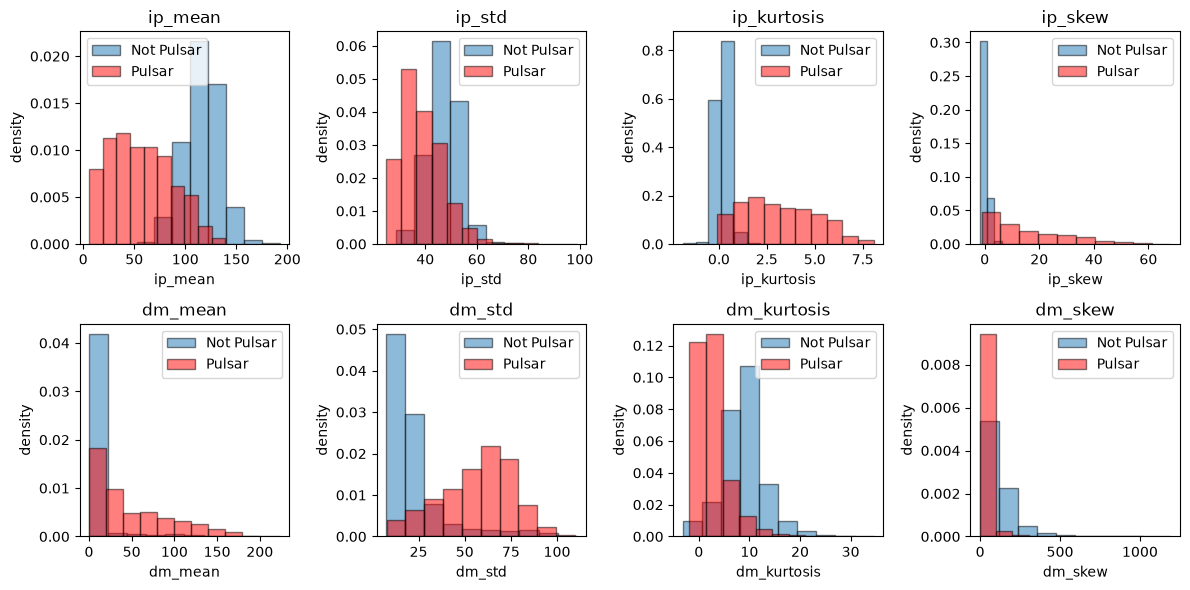

In [ ]:
feature = columns[0:8]
fig, ax = plt.subplots(2, 4, figsize=(12, 6))


for column_name, subplot_ax in zip(feature, ax.flat):
  subplot_ax.hist(df[df['label'] == 0][column_name], label='Not Pulsar', edgecolor='black', density=True, alpha=0.5)
  subplot_ax.hist(df[df['label'] == 1][column_name], label='Pulsar', edgecolor='black', density=True, color='red', alpha=0.5)
  subplot_ax.legend()
  subplot_ax.set_xlabel(column_name)
  subplot_ax.set_ylabel('density')
  subplot_ax.set_title(column_name)

fig.tight_layout()
fig.savefig('figures/01_features_by_class.png', dpi=150)
